# ISO 20414:2020 — Test 4: Movement around a corner

20 occupants uniformly distributed in a 2 m x 4 m area at one end of an L-shaped hallway, pre-evacuation time 0, walking speed 1 m/s (ISO 20414:2020 Table 5). They must navigate the corner without penetrating the boundaries.

In [1]:
from datetime import datetime
print(f"Executed on {datetime.now().astimezone().strftime('%d %B %Y, %H:%M %Z')}")

Executed on 15 October 2026, 17:29 CEST


In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import pedpy
from shapely.geometry import Point

from jupedsim_scenarios import load_scenario, run_scenario

In [3]:
plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "#f7f7f5",
    "axes.edgecolor": "#3a3a3a",
    "axes.labelcolor": "#1d1d1d",
    "axes.titleweight": "bold",
    "axes.grid": True,
    "grid.alpha": 0.3,
    "font.size": 11,
    "figure.figsize": (8, 5),
})

In [4]:
import numpy as np

# House style for the V&V figures (plain matplotlib; applied per figure via rc_context).
from matplotlib.colors import to_rgba
from matplotlib.lines import Line2D
from matplotlib.patches import Patch, PathPatch
from matplotlib.patches import Polygon as MplPolygon
from matplotlib.path import Path as MplPath

VV_BLUE, VV_ORANGE, VV_RED, VV_GREEN = "#0072B2", "#E69F00", "#D55E00", "#009E73"
VV_RC = {
    "figure.facecolor": "white", "axes.facecolor": "white", "figure.dpi": 150,
    "font.family": "DejaVu Sans", "font.size": 10,
    "axes.grid": True, "grid.color": "#e5e5e5", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.edgecolor": "lightgrey", "axes.labelcolor": "dimgrey",
    "axes.titlecolor": "#333333", "axes.titleweight": "normal", "axes.titlesize": 11,
    "axes.spines.left": False, "axes.spines.bottom": False,
    "axes.spines.top": False, "axes.spines.right": False,
    "xtick.color": "dimgrey", "ytick.color": "dimgrey",
    "xtick.major.size": 0, "ytick.major.size": 0,
    "legend.frameon": True, "legend.facecolor": "white", "legend.framealpha": 0.8,
    "legend.edgecolor": "lightgrey", "legend.labelcolor": "dimgrey", "legend.fontsize": 9,
}


def vv_polygon_patch(geom, **kwargs):
    """Matplotlib patch for a shapely (Multi)Polygon, holes included."""
    verts, codes = [], []
    for part in getattr(geom, "geoms", [geom]):
        for ring in [part.exterior, *part.interiors]:
            xy = np.asarray(ring.coords)
            verts.extend(xy)
            codes += [MplPath.MOVETO] + [MplPath.LINETO] * (len(xy) - 2) + [MplPath.CLOSEPOLY]
    return PathPatch(MplPath(verts, codes), **kwargs)


def vv_draw_scenario(ax, scenario, starts=True, pad=0.04):
    """Draw walkable area, exits and start areas of a loaded scenario; return legend handles."""
    ax.add_patch(vv_polygon_patch(scenario.walkable_polygon, facecolor="#eeeeee",
                                  edgecolor="dimgrey", linewidth=1.4, zorder=1))
    handles = [Patch(facecolor="#eeeeee", edgecolor="dimgrey", label="walkable area")]
    if starts:
        for dist in scenario.distributions.values():
            ax.add_patch(MplPolygon(dist["coordinates"], closed=True,
                                    facecolor=to_rgba(VV_BLUE, 0.15), edgecolor=VV_BLUE,
                                    linestyle="--", linewidth=1.2, hatch="..", zorder=2))
        handles.append(Patch(facecolor=to_rgba(VV_BLUE, 0.15), edgecolor=VV_BLUE,
                             linestyle="--", hatch="..", label="start area"))
    for ex in scenario.exits.values():
        ax.add_patch(MplPolygon(ex["coordinates"], closed=True,
                                facecolor=to_rgba(VV_RED, 0.35), edgecolor=VV_RED,
                                linewidth=1.2, hatch="///", zorder=3))
    if scenario.exits:
        handles.append(Patch(facecolor=to_rgba(VV_RED, 0.35), edgecolor=VV_RED,
                             hatch="///", label="exit"))
    minx, miny, maxx, maxy = scenario.walkable_polygon.bounds
    m = pad * max(maxx - minx, maxy - miny)
    ax.set_xlim(minx - m, maxx + m)
    ax.set_ylim(miny - m, maxy + m)
    ax.set_aspect("equal")
    ax.grid(False)
    ax.set_xlabel("x [m]")
    ax.set_ylabel("y [m]")
    return handles


def vv_agent_count(scenario):
    """Total number of agents placed by the scenario's start areas."""
    return sum(int(d.get("parameters", {}).get("number", 0)) for d in scenario.distributions.values())

## Load and run

In [5]:
SCENARIO_ZIP = Path("scenario_files") / "Iso-04-corner.zip"
scenario = load_scenario(str(SCENARIO_ZIP))
print(scenario.summary())
result = run_scenario(scenario, seed=42)
walkable = scenario.walkable_polygon
df = result.trajectory_dataframe()

Scenario: scenario_files/Iso-04-corner.zip
  Model:         CollisionFreeSpeedModel
  Seed:          42
  Max time:      120s
  Exits:         1
  Distributions: 1
  Stages:        0
  Zones:         0
  Journeys:      1
  Agents:        ~20
  Journey elems: 2
  Route:         1 distribution, 0 checkpoint, 1 exit
  Sequence:      jps-distributions_0 -> jps-exits_0
    jps-distributions_0: 20 agents


## Scenario figure

L-shaped corridor: the agents start in the 2 m x 4 m area at one end and exit at the other.

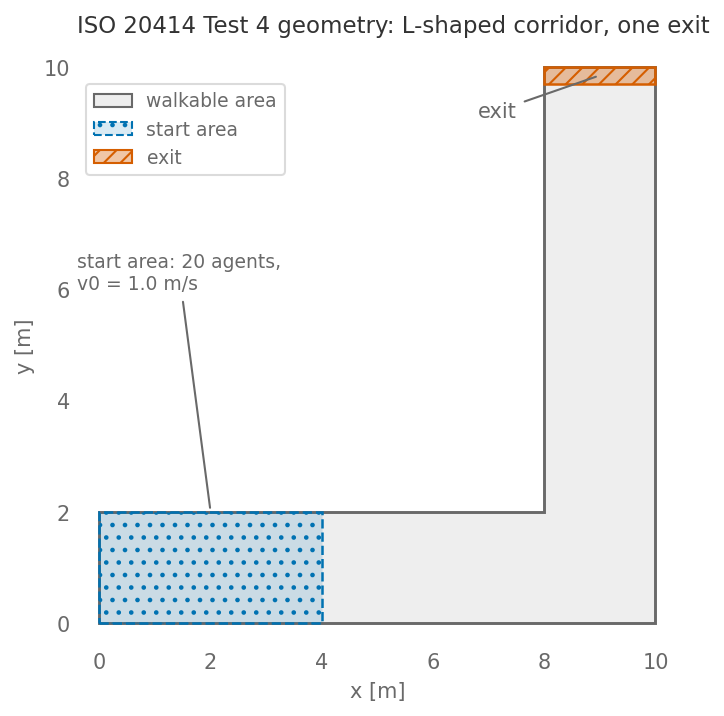

In [6]:
# Scenario geometry from the loaded ZIP.
from shapely.geometry import Polygon
with plt.rc_context(VV_RC):
    fig, ax = plt.subplots(figsize=(5.6, 5.2))
    handles = vv_draw_scenario(ax, scenario)
    for dist in scenario.distributions.values():
        poly = Polygon(dist["coordinates"])
        p = dist["parameters"]
        ax.annotate(f"start area: {p['number']} agents,\nv0 = {p['v0']} m/s",
                    xy=(poly.centroid.x, poly.bounds[3]), xytext=(0.0, 0.62), textcoords="axes fraction",
                    ha="left", va="center", color="dimgrey", fontsize=9,
                    arrowprops={"arrowstyle": "-", "color": "dimgrey"})
    for ex in scenario.exits.values():
        e = Polygon(ex["coordinates"]).centroid
        ax.annotate("exit", xy=(e.x, e.y), xytext=(-40, -20), textcoords="offset points",
                    ha="right", color="dimgrey", arrowprops={"arrowstyle": "-", "color": "dimgrey"})
    ax.set_title("ISO 20414 Test 4 geometry: L-shaped corridor, one exit", loc="left")
    ax.legend(handles=handles, loc="upper left", bbox_to_anchor=(0.0, 0.95))
    plt.show()

## Boundary-penetration check

In [7]:
walkable_with_tol = walkable.buffer(0.001)
outside = []
for _, row in df.iterrows():
    if not walkable_with_tol.contains(Point(row.x, row.y)):
        outside.append((int(row.id), int(row.frame), float(row.x), float(row.y)))
print(f'{len(outside)} / {len(df)} trajectory points outside walkable area')

0 / 3861 trajectory points outside walkable area


## Flow rates into and out of the corner

Agents travel along the horizontal leg (crossing x = 6) into the corner, then up the vertical leg (crossing y = 6) out of it. ISO suggests comparing the flow entering the corner (horizontal leg, x = 6) and leaving it (vertical leg, y = 6) to check whether the corner causes a bottleneck.

In [8]:
def crossings(df, axis, value, rate):
    ts = []
    for _, sub in df.sort_values(['id', 'frame']).groupby('id'):
        coord = sub[axis]
        before = sub[coord < value]; after = sub[coord >= value]
        if len(before) and len(after):
            ts.append(after.iloc[0].frame / rate)
    return sorted(ts)
enter = crossings(df, 'x', 6.0, result.frame_rate)
leave = crossings(df, 'y', 6.0, result.frame_rate)
def flow(ts):
    return (len(ts) - 1) / (ts[-1] - ts[0]) if len(ts) >= 2 and ts[-1] > ts[0] else float('nan')
print(f'flow entering corner (x=6): {flow(enter):.3f} p/s ({len(enter)} agents)')
print(f'flow leaving corner  (y=6): {flow(leave):.3f} p/s ({len(leave)} agents)')

flow entering corner (x=6): 2.000 p/s (20 agents)
flow leaving corner  (y=6): 1.338 p/s (20 agents)


## Plot trajectories

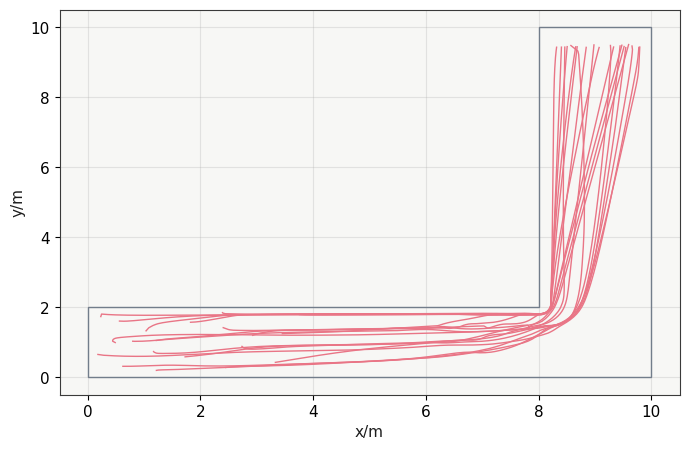

In [9]:
traj = pedpy.TrajectoryData(df[['id', 'frame', 'x', 'y']].copy(), frame_rate=result.frame_rate)
wa = pedpy.WalkableArea(walkable)
pedpy.plot_trajectories(walkable_area=wa, traj=traj)
plt.show()

## Result figure

Left: trajectories. Right: distance of every agent centre to the nearest boundary segment. Acceptance: no trajectory point outside the walkable area (1 mm tolerance) and full evacuation.

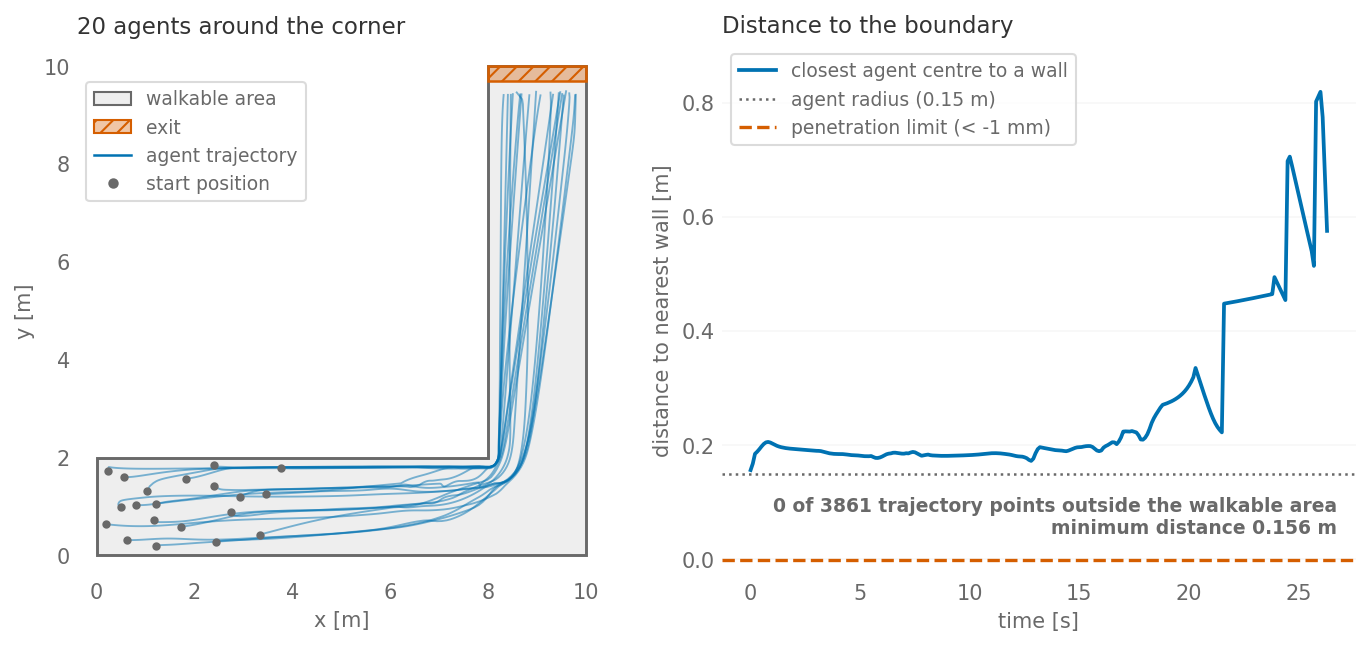

In [10]:
# Trajectories in the corner geometry and distance of every agent centre to the nearest wall.
import shapely
from matplotlib.collections import LineCollection

wall_dist = shapely.distance(walkable.boundary, shapely.points(df["x"], df["y"]))
with plt.rc_context(VV_RC):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.6), gridspec_kw={"width_ratios": [1, 1.2]})
    handles = vv_draw_scenario(ax1, scenario, starts=False)
    segs = [g.sort_values("frame")[["x", "y"]].to_numpy() for _, g in df.groupby("id")]
    ax1.add_collection(LineCollection(segs, colors=VV_BLUE, linewidths=0.9, alpha=0.5, zorder=4))
    ax1.plot([s[0, 0] for s in segs], [s[0, 1] for s in segs], "o", color="dimgrey", ms=3, zorder=5)
    handles += [Line2D([], [], color=VV_BLUE, lw=1.2, label="agent trajectory"),
                Line2D([], [], color="dimgrey", marker="o", ls="", ms=4, label="start position")]
    ax1.legend(handles=handles, loc="upper left", bbox_to_anchor=(0.0, 0.95))
    ax1.set_title(f"{df['id'].nunique()} agents around the corner", loc="left")
    min_dist = pd.Series(wall_dist).groupby(df["frame"].to_numpy()).min()
    radius = next(iter(scenario.distributions.values()))["parameters"]["radius"]
    ax2.plot(min_dist.index / result.frame_rate, min_dist.to_numpy(), color=VV_BLUE, lw=1.8,
             label="closest agent centre to a wall")
    ax2.axhline(radius, color="dimgrey", ls=":", lw=1.2, label=f"agent radius ({radius:g} m)")
    ax2.axhline(-0.001, color=VV_RED, ls="--", lw=1.6, label="penetration limit (< -1 mm)")
    ax2.set_ylim(-0.03, min_dist.max() * 1.1)
    ax2.set_xlabel("time [s]")
    ax2.set_ylabel("distance to nearest wall [m]")
    ax2.set_title("Distance to the boundary", loc="left")
    ax2.legend(loc="upper left")
    ax2.text(0.97, 0.08, f"{len(outside)} of {len(df)} trajectory points outside the walkable area\n"
             f"minimum distance {wall_dist.min():.3f} m", transform=ax2.transAxes, ha="right",
             color="dimgrey", fontweight="semibold", fontsize=9)
    ax2.grid(axis="x", visible=False)
    plt.show()

## Acceptance

In [11]:
assert len(outside) == 0, outside[:5]
assert result.agents_remaining == 0, result.agents_remaining
print(f'evacuation time = {result.evacuation_time:.2f} s')
result.cleanup()

evacuation time = 26.39 s


1